In [10]:
# ==========================================
# 0. KHAI BÁO THƯ VIỆN VÀ THIẾT BỊ
# ==========================================
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset
from torchsummary import summary
import matplotlib.pyplot as plt
import numpy as np
import os
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Thiết bị tính toán
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Số ảnh huấn luyện: 1213
Số ảnh kiểm chứng: 260
Số ảnh kiểm tra: 261


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


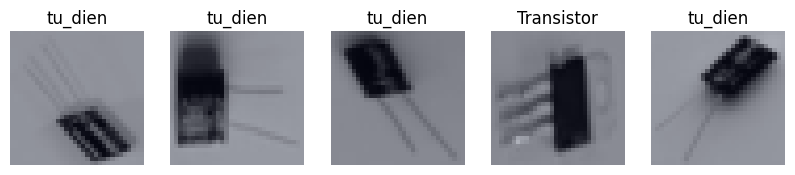

In [11]:
# ==========================================
# 1. TIỀN XỬ LÝ VÀ NẠP DỮ LIỆU 
# ==========================================
# Đường dẫn tới thư mục dataset trên Kaggle
data_dir = '/kaggle/input/datasets/toantransong/linh-kien-dien-tu/Component_dataset' 

transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomHorizontalFlip(), # Augmentation nhẹ để giảm Overfitting
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

# Đọc toàn bộ dữ liệu và tự động gán nhãn
full_dataset = datasets.ImageFolder(
    root=data_dir,
    transform=transform
)

# Xác định tên các lớp
class_names = full_dataset.classes
num_classes = len(class_names)
total_size = len(full_dataset)

train_size = int(0.7 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

generator = torch.Generator().manual_seed(42)

train_data, val_data, test_data = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=generator
)
# Tối ưu DataLoader để giảm nghẽn CPU
train_loader = DataLoader(train_data, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False, num_workers=4, pin_memory=True)
valid_loader = DataLoader(val_data, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)
print("Số ảnh huấn luyện:", len(train_data))
print("Số ảnh kiểm chứng:", len(val_data))
print("Số ảnh kiểm tra:", len(test_data))

# Trực quan hóa một số hình ảnh mẫu
plt.figure(figsize=(10, 5))
images, labels = next(iter(train_loader))
for i in range(5):
    plt.subplot(1, 5, i+1)
    img = images[i].permute(1, 2, 0).numpy()
    img = np.clip(img * 0.2 + 0.5, 0, 1) # Un-normalize xấp xỉ
    plt.imshow(img)
    plt.title(class_names[labels[i]])
    plt.axis('off')
plt.show()

In [12]:
# ==========================================
# 2. XÂY DỰNG KIẾN TRÚC MẠNG CNN
# ==========================================
class SIMPLE_CNN(nn.Module):
    def __init__(self):
        super(SIMPLE_CNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = SIMPLE_CNN().to(device)
summary(model, (3, 32, 32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 32, 32]             896
       BatchNorm2d-2           [-1, 32, 32, 32]              64
              ReLU-3           [-1, 32, 32, 32]               0
         MaxPool2d-4           [-1, 32, 16, 16]               0
            Conv2d-5           [-1, 64, 16, 16]          18,496
       BatchNorm2d-6           [-1, 64, 16, 16]             128
              ReLU-7           [-1, 64, 16, 16]               0
         MaxPool2d-8             [-1, 64, 8, 8]               0
            Conv2d-9            [-1, 128, 8, 8]          73,856
      BatchNorm2d-10            [-1, 128, 8, 8]             256
             ReLU-11            [-1, 128, 8, 8]               0
        MaxPool2d-12            [-1, 128, 4, 4]               0
          Flatten-13                 [-1, 2048]               0
           Linear-14                  [

In [13]:
# ==========================================
# 3. HUẤN LUYỆN VÀ ĐÁNH GIÁ TRONG TỪNG EPOCH
# ==========================================
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 20
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_acc = 0.0

for epoch in range(epochs):
    # Training phase
    model.train()
    t_loss, t_corr = 0.0, 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        t_loss += loss.item()
        t_corr += (outputs.argmax(1) == labels).sum().item()
    
    # Validation phase
    model.eval()
    v_loss, v_corr = 0.0, 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            v_loss += criterion(outputs, labels).item()
            v_corr += (outputs.argmax(1) == labels).sum().item()
            
    # Lưu chỉ số
    history['train_loss'].append(t_loss/len(train_loader))
    history['val_loss'].append(v_loss/len(test_loader))
    history['train_acc'].append(100*t_corr/len(train_data))
    history['val_acc'].append(100*v_corr/len(test_data))
    
    # Lưu Best Model
    if history['val_acc'][-1] > best_acc:
        best_acc = history['val_acc'][-1]
        torch.save(model.state_dict(), 'best_electronic.pth')
        
    # In tiêu đề bảng (thực hiện một lần trước vòng lặp epochs)
    if epoch == 0:
        print(f"{'Epoch':<8} | {'Train Loss':<10} | {'Val Loss':<10} | {'Train Acc':<10} | {'Val Acc':<10}")
        print("-" * 65)

    # In các thông số chi tiết của từng epoch
    print(f"{epoch+1:<8} | "
          f"{history['train_loss'][-1]:<10.4f} | "
          f"{history['val_loss'][-1]:<10.4f} | "
          f"{history['train_acc'][-1]:<9.2f}% | "
          f"{history['val_acc'][-1]:<9.2f}%")

Epoch    | Train Loss | Val Loss   | Train Acc  | Val Acc   
-----------------------------------------------------------------
1        | 0.8052     | 0.3426     | 65.13    % | 89.66    %
2        | 0.1841     | 0.1131     | 93.73    % | 95.02    %
3        | 0.1211     | 0.0454     | 95.80    % | 97.70    %
4        | 0.0992     | 0.0356     | 96.13    % | 98.85    %
5        | 0.0798     | 0.0968     | 97.36    % | 96.17    %
6        | 0.0529     | 0.1482     | 98.10    % | 96.93    %
7        | 0.0567     | 0.0230     | 97.94    % | 99.62    %
8        | 0.0419     | 0.3231     | 98.43    % | 88.12    %
9        | 0.0471     | 0.0231     | 97.69    % | 98.85    %
10       | 0.0382     | 0.0309     | 98.85    % | 98.85    %
11       | 0.0245     | 0.7564     | 99.01    % | 81.99    %
12       | 0.0332     | 0.0117     | 98.60    % | 99.62    %
13       | 0.0203     | 0.1255     | 99.26    % | 95.02    %
14       | 0.0134     | 0.0271     | 99.59    % | 99.23    %
15       | 0.0152  

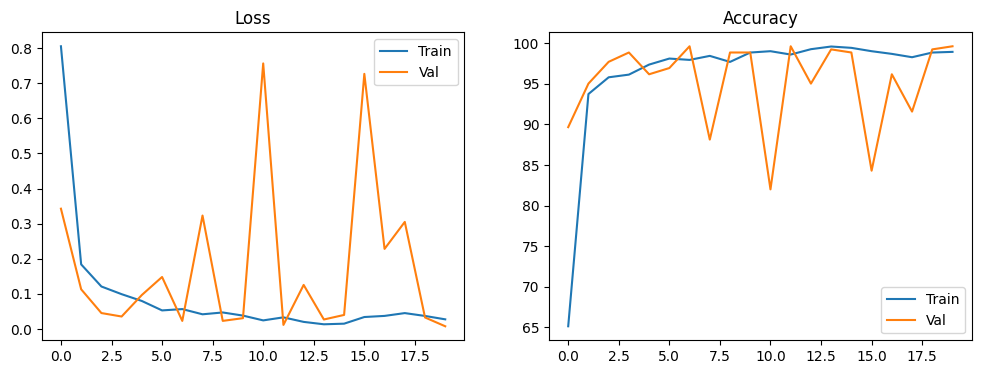

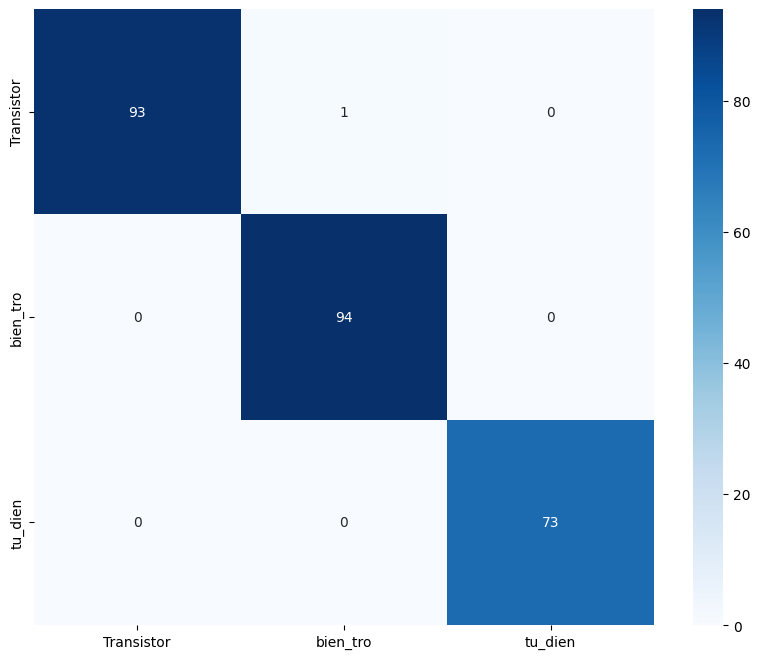

In [15]:
# ==========================================
# 4. TRỰC QUAN HÓA QUÁ TRÌNH HUẤN LUYỆN
# ==========================================
# Biểu đồ Loss và Acc
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1); plt.plot(history['train_loss'], label='Train'); plt.plot(history['val_loss'], label='Val'); plt.legend(); plt.title('Loss')
plt.subplot(1, 2, 2); plt.plot(history['train_acc'], label='Train'); plt.plot(history['val_acc'], label='Val'); plt.legend(); plt.title('Accuracy')
plt.show()

# Ma trận nhầm lẫn
model.load_state_dict(torch.load('best_electronic.pth'))
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, lbs in test_loader:
        outputs = model(imgs.to(device))
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(lbs.numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d',cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.show()


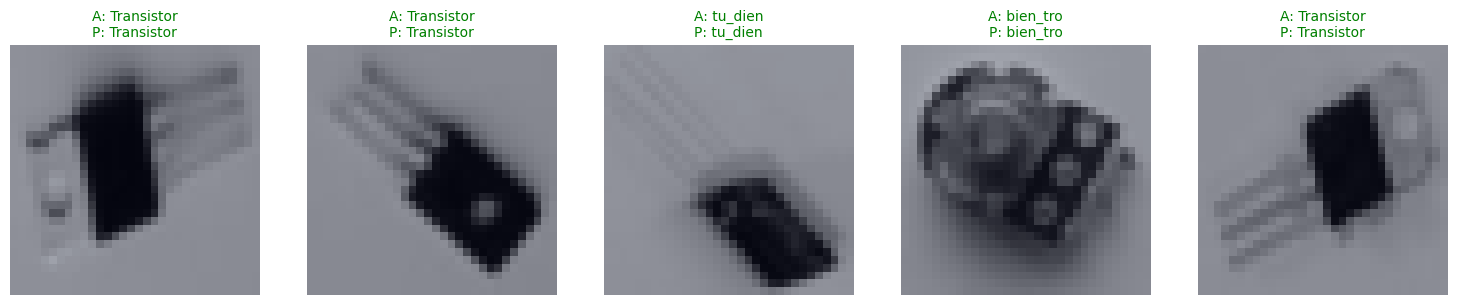

In [18]:
# ==========================================
#   5. TẢI LẠI MÔ HÌNH ĐỂ SỬ DỤNG
# ==========================================

# 1. Tải lại trạng thái trọng số tốt nhất đã lưu trong quá trình huấn luyện
model.load_state_dict(torch.load('best_electronic.pth'))
model.eval() # Thiết lập mô hình ở chế độ dự báo (Inference)

# 2. Cấu hình hiển thị và lấy mẫu ngẫu nhiên
plt.figure(figsize=(15, 3))
num_samples = 5

for i in range(num_samples):
    # Chọn ngẫu nhiên một chỉ số trong tập dữ liệu kiểm tra
    idx = np.random.randint(len(test_data))
    img_t, label = test_data[idx]
    
    # Thực hiện dự báo (cần thêm một chiều batch bằng unsqueeze)
    with torch.no_grad():
        # Đưa ảnh lên cùng thiết bị với mô hình (CPU/GPU)
        output = model(img_t.unsqueeze(0).to(device))
        pred = output.argmax(1).item()
    
# 3. Trực quan hóa kết quả
    plt.subplot(1, num_samples, i+1)
    
    # Chuyển đổi Tensor về dạng ảnh để hiển thị (Un-normalize xấp xỉ)
    img_disp = img_t.permute(1, 2, 0).numpy()
    img_disp = np.clip(img_disp * 0.2 + 0.5, 0, 1)
    
    plt.imshow(img_disp)
    
    # Hiển thị nhãn Thực tế (A - Actual) và Dự báo (P - Predicted)
    # Sử dụng màu xanh nếu dự báo đúng, màu đỏ nếu dự báo sai
    title_color = "green" if label == pred else "red"
    plt.title(f"A: {class_names[label]}\nP: {class_names[pred]}", 
              color=title_color, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()